# C0 — results and the error landscape

Where do the C0 classifiers actually fail, and where on the score axis do those failures sit?

This notebook **reads only prediction CSVs already on disk** (`C0_custom/{task}/{split}_c0_{task}.csv`);
nothing is trained or re-inferred. It covers all four C0 tasks so effusion can be read
*relative to* the others rather than in isolation.

| § | Content |
|---|---|
| 0 | Provenance + load |
| 1 | C0 results — headline metrics and confusion matrices |
| 2 | Score distributions — where the probability mass sits |
| 3 | **Where the errors fall** — error mass, error rate vs confidence, FP/FN split, rejection curves, calibration |
| 4 | Saturation: the cross-task comparison that matters for the thesis |

**Operating point.** Each model has its own Youden-J threshold in `threshold.txt`
(effusion 0.5634, pneumothorax 0.2982, cardiomegaly 0.6839, RSNA 0.4517). Because these
differ, anything compared *across* tasks uses the threshold-relative
**margin = |prob − thr|**, not a fixed [0.2, 0.8] window — a fixed window is not
comparable when the operating points differ by 0.39.

---
## §0 — Provenance and load

Two splits per task, plus the C2 set:

- `train_c0_{task}.csv` / `val_c0_{task}.csv` — C0's **own** train/val split (patient-disjoint, 50/50).
- `C2_custom/{task}/c2_data.csv` — the set the downstream method consumes.

The C2 set is carved out of C0's **val** split, so C0 never saw those images in training.
The load cell asserts this rather than assuming it.

In [1]:
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from sklearn.metrics import roc_auc_score, confusion_matrix, roc_curve

BASE    = '/zhome/d0/a/221493/thesis'
RESULTS = '/work3/s251710/thesis_results'
OUT     = f'{BASE}/notebooks/images'
os.makedirs(OUT, exist_ok=True)

TASKS       = ['effusion', 'cardiomegaly', 'pneumothorax']
TASK_LABEL  = {'effusion': 'Pleural effusion', 'cardiomegaly': 'Cardiomegaly', 'pneumothorax': 'Pneumothorax'}

# Colours: role-based, colourblind-safe (Wong). Grey = correct, red = error.
C_CORRECT, C_ERROR = '#BFBFBF', '#CC0000'
C_NEG, C_POS       = '#0072B2', '#E69F00'   # true=0 (deep blue), true=1 (amber)
C_FP, C_FN         = '#56B4E9', '#D55E00'   # false positive, false negative

plt.style.use('seaborn-v0_8-white')
plt.rcParams.update({
    'font.family': 'sans-serif', 'font.size': 11,
    'axes.titlesize': 12, 'axes.labelsize': 11,
    'xtick.labelsize': 10, 'ytick.labelsize': 10, 'legend.fontsize': 9,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.linewidth': 1.1, 'grid.alpha': 0.3, 'grid.linewidth': 0.6,
    'figure.dpi': 110, 'savefig.dpi': 220, 'savefig.bbox': 'tight',
})
pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', lambda v: f'{v:.4f}')
print('ok')

ok


In [2]:
# ── Load ──────────────────────────────────────────────────────────────────────
# The CSVs carry 1024 embedding columns + 7 internal-probe columns; read only the
# handful of scalar columns we need, otherwise this is ~1 GB of needless I/O.
SCALARS = ['path', 'prob', 'true', 'pred', 'correct', 'margin']

def _read(path):
    have = pd.read_csv(path, nrows=0).columns
    return pd.read_csv(path, usecols=[c for c in SCALARS if c in have])

THR, D = {}, {}          # D[(task, split)] -> DataFrame
for t in TASKS:
    mdir = f'{RESULTS}/C0_custom/{t}'
    THR[t] = float(open(f'{mdir}/threshold.txt').read().strip())
    for s in ['train', 'val']:
        D[(t, s)] = _read(f'{mdir}/{s}_c0_{t}.csv')
    D[(t, 'c2')] = _read(f'{RESULTS}/C2_custom/{t}/c2_data.csv')

# Recompute pred/correct/margin from the stored threshold so one rule governs the
# whole notebook, rather than trusting columns written by four different scripts.
for k, d in D.items():
    thr = THR[k[0]]
    d['pred']    = (d['prob'] >= thr).astype(int)
    d['true']    = d['true'].astype(int)
    d['correct'] = (d['pred'] == d['true']).astype(int)
    d['margin']  = (d['prob'] - thr).abs()

# Provenance assertions: C2 ⊂ val, and C2 ∩ C0-train = ∅.
rows = []
for t in TASKS:
    tr, va, c2 = (set(D[(t, s)].path) for s in ['train', 'val', 'c2'])
    assert c2 <= va and not (c2 & tr), f'{t}: C2 provenance broken'
    rows.append({'task': t, 'thr': THR[t], 'C0_train': len(tr), 'C0_val': len(va),
                 'C2': len(c2), 'C2 in val': len(c2 & va), 'C2 in train': len(c2 & tr)})
print('C2 is a strict subset of C0-val, disjoint from C0-train, in all four tasks.\n')
pd.DataFrame(rows).set_index('task')

C2 is a strict subset of C0-val, disjoint from C0-train, in all four tasks.



,thr,C0_train,C0_val,C2,C2 in val,C2 in train
task,,,,,,
effusion,0.5634,60141,61442,45155,45155,0
cardiomegaly,0.6839,18826,19290,13929,13929,0
pneumothorax,0.2982,37873,37916,27722,27722,0


---
## §1 — C0 results

`ECE` is expected calibration error over 15 equal-width bins — how far the stated
confidence is from the observed accuracy. `band` is the share of samples with
margin ≤ 0.15, i.e. sitting within 0.15 of the decision threshold.

In [3]:
def ece(y, p, n_bins=15):
    conf = np.where(p >= 0.5, p, 1 - p)          # confidence in the argmax class
    hit  = ((p >= 0.5).astype(int) == y).astype(float)
    edges = np.linspace(0, 1, n_bins + 1)
    idx = np.clip(np.digitize(conf, edges[1:-1]), 0, n_bins - 1)
    out = 0.0
    for b in range(n_bins):
        m = idx == b
        if m.any():
            out += m.mean() * abs(hit[m].mean() - conf[m].mean())
    return out


def metrics(d, thr, band=0.15):
    y, p, yh = d.true.values, d.prob.values, d.pred.values
    tn, fp, fn, tp = confusion_matrix(y, yh, labels=[0, 1]).ravel()
    err = (yh != y)
    return {
        'n': len(d), 'prev': y.mean(), 'thr': thr,
        'AUC': roc_auc_score(y, p), 'acc': (yh == y).mean(),
        'bal_acc': 0.5 * (tp / max(tp + fn, 1) + tn / max(tn + fp, 1)),
        'sens': tp / max(tp + fn, 1), 'spec': tn / max(tn + fp, 1),
        'FP': fp, 'FN': fn, 'n_err': int(err.sum()), 'err_rate': err.mean(),
        'ECE': ece(y, p),
        'band': (d.margin <= band).mean(),
        'err_in_band': (d.margin[err] <= band).mean() if err.any() else np.nan,
    }

MET = pd.DataFrame(
    {(TASK_LABEL[t], s): metrics(D[(t, s)], THR[t]) for t in TASKS for s in ['val', 'c2']}
).T
MET.index.names = ['task', 'split']
MET[['n', 'prev', 'thr', 'AUC', 'acc', 'bal_acc', 'sens', 'spec',
     'FP', 'FN', 'n_err', 'err_rate', 'ECE']].astype(
    {'n': int, 'FP': int, 'FN': int, 'n_err': int})

n   prev    thr    AUC    acc  bal_acc   sens   spec    FP    FN  n_err  err_rate    ECE
task             split                                                                                              
Pleural effusion val    61442 0.7136 0.5634 0.9566 0.9109   0.9061 0.9175 0.8947  1854  3618   5472    0.0891 0.0038
                 c2     45155 0.7645 0.5634 0.9545 0.9172   0.9046 0.9285 0.8807  1268  2469   3737    0.0828 0.0042
Cardiomegaly     val    19290 0.7102 0.6839 0.9268 0.8530   0.8584 0.8457 0.8710   721  2114   2835    0.1470 0.0056
                 c2     13929 0.7535 0.6839 0.9370 0.8762   0.8687 0.8834 0.8541   501  1224   1725    0.1238 0.0054
Pneumothorax     val    37916 0.2584 0.2982 0.8182 0.7589   0.7379 0.6944 0.7814  6146  2994   9140    0.2411 0.0175
                 c2     27722 0.2883 0.2982 0.8131 0.7442   0.7327 0.7055 0.7598  4738  2354   7092    0.2558 0.0244

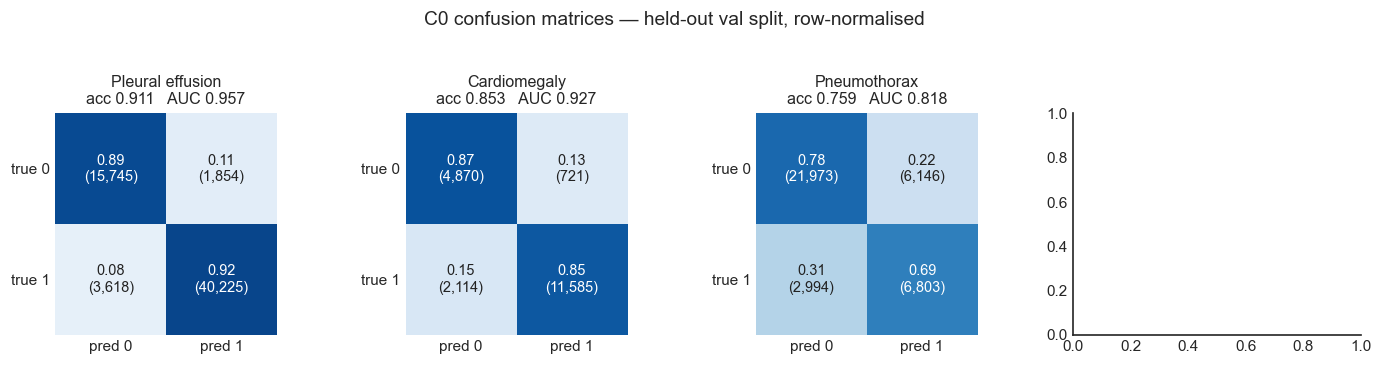

In [4]:
# Held-out (C0-val) confusion matrices, row-normalised, with raw counts annotated.
fig, axes = plt.subplots(1, 4, figsize=(13, 3.1))
for ax, t in zip(axes, TASKS):
    d = D[(t, 'val')]
    cm = confusion_matrix(d.true, d.pred, labels=[0, 1])
    cmn = cm / cm.sum(1, keepdims=True)
    ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{cmn[i, j]:.2f}\n({cm[i, j]:,})', ha='center', va='center',
                    fontsize=9.5, color='white' if cmn[i, j] > 0.55 else '#222')
    ax.set_xticks([0, 1], ['pred 0', 'pred 1'])
    ax.set_yticks([0, 1], ['true 0', 'true 1'])
    ax.set_title(f'{TASK_LABEL[t]}\nacc {MET.loc[(TASK_LABEL[t], "val"), "acc"]:.3f}   '
                 f'AUC {MET.loc[(TASK_LABEL[t], "val"), "AUC"]:.3f}', fontsize=10.5)
    for s in ax.spines.values():
        s.set_visible(False)
fig.suptitle('C0 confusion matrices — held-out val split, row-normalised', y=1.06, fontsize=12.5)
fig.tight_layout(); fig.savefig(f'{OUT}/c0_error_confusion.png'); plt.show()

---
## §2 — Score distributions

Where the probability mass sits, split by ground truth. The gap between the two humps is
the separability the threshold has to exploit; the overlap region is where errors are
*forced*.

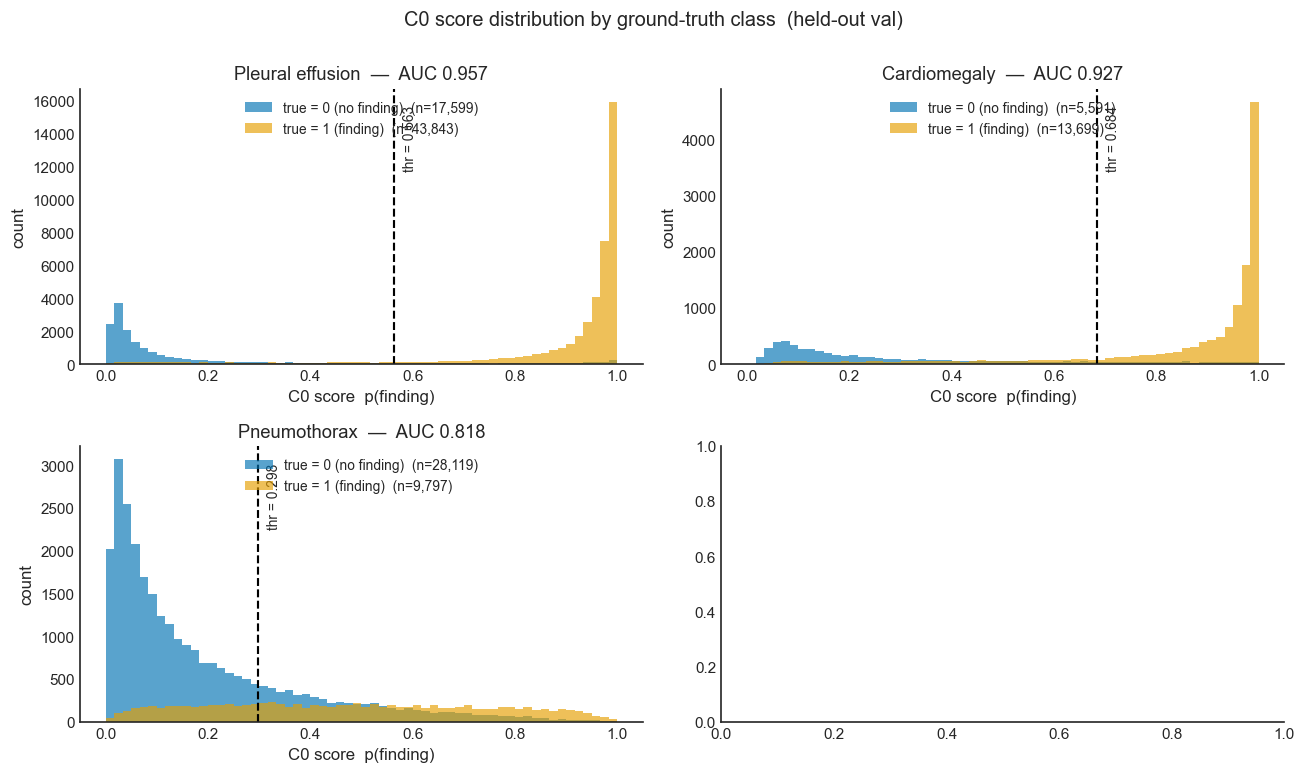

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
bins = np.linspace(0, 1, 61)
for ax, t in zip(axes.ravel(), TASKS):
    d = D[(t, 'val')]
    for lab, col, name in [(0, C_NEG, 'true = 0 (no finding)'), (1, C_POS, 'true = 1 (finding)')]:
        ax.hist(d.prob[d.true == lab], bins=bins, color=col, alpha=0.65,
                label=f'{name}  (n={int((d.true == lab).sum()):,})')
    ax.axvline(THR[t], color='k', ls='--', lw=1.4)
    ax.annotate(f'thr = {THR[t]:.3f}', xy=(THR[t], ax.get_ylim()[1] * 0.94),
                xytext=(6, 0), textcoords='offset points', fontsize=9, rotation=90, va='top')
    ax.set_title(f'{TASK_LABEL[t]}  —  AUC {MET.loc[(TASK_LABEL[t], "val"), "AUC"]:.3f}')
    ax.set_xlabel('C0 score  p(finding)'); ax.set_ylabel('count'); ax.legend(loc='upper center')
fig.suptitle('C0 score distribution by ground-truth class  (held-out val)', y=1.00, fontsize=13)
fig.tight_layout(); fig.savefig(f'{OUT}/c0_error_score_dist.png'); plt.show()

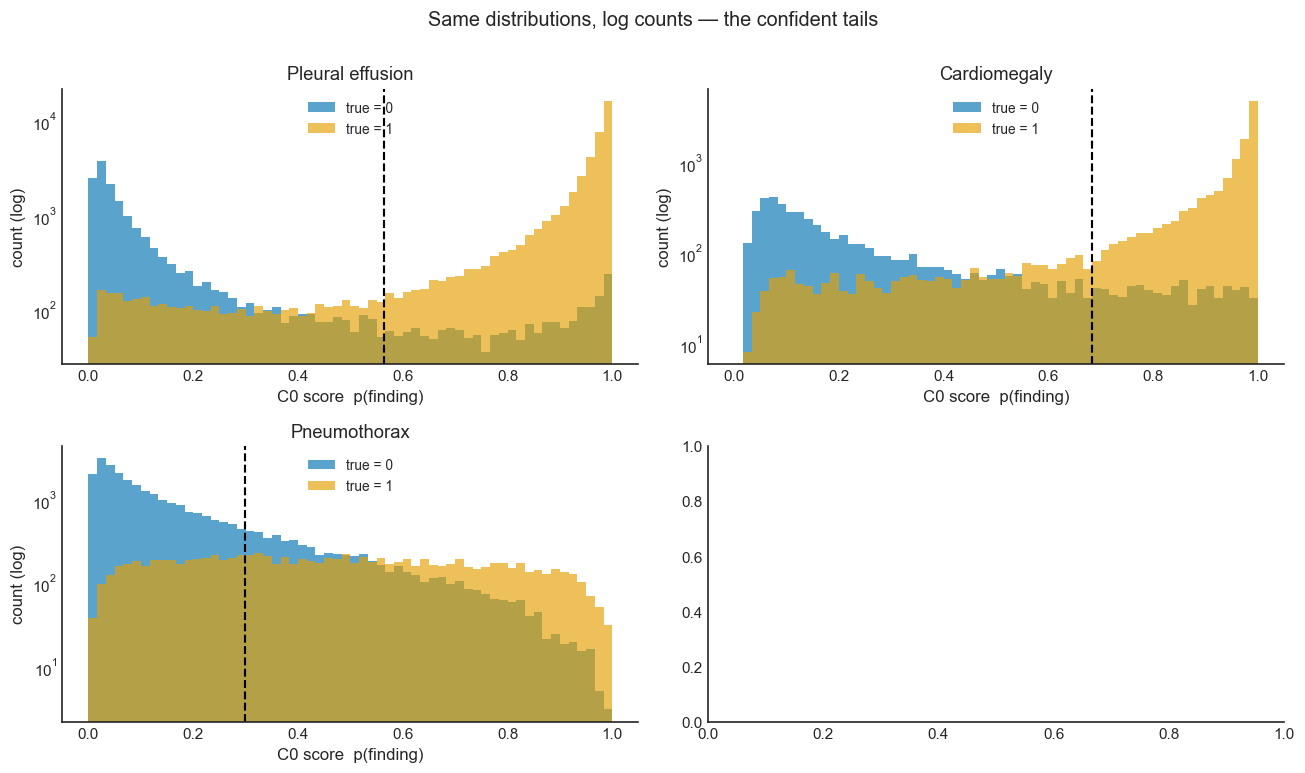

In [6]:
# Same thing on a log count axis — the tails are the whole story for effusion and the
# linear axis flattens them into nothing.
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, t in zip(axes.ravel(), TASKS):
    d = D[(t, 'val')]
    for lab, col in [(0, C_NEG), (1, C_POS)]:
        ax.hist(d.prob[d.true == lab], bins=bins, color=col, alpha=0.65, label=f'true = {lab}')
    ax.axvline(THR[t], color='k', ls='--', lw=1.4)
    ax.set_yscale('log')
    ax.set_title(TASK_LABEL[t]); ax.set_xlabel('C0 score  p(finding)')
    ax.set_ylabel('count (log)'); ax.legend(loc='upper center')
fig.suptitle('Same distributions, log counts — the confident tails', y=1.00, fontsize=13)
fig.tight_layout(); fig.savefig(f'{OUT}/c0_error_score_dist_log.png'); plt.show()

---
## §3 — Where the errors fall

### 3a. Error mass on the score axis

Grey = correct, red = error, stacked. The red area is the total pool of supervision
available to any downstream error-prediction method, and its *shape* says whether that
pool sits near the boundary (learnable from confidence alone) or out in the confident
tails (where confidence is useless and something else must explain the failure).

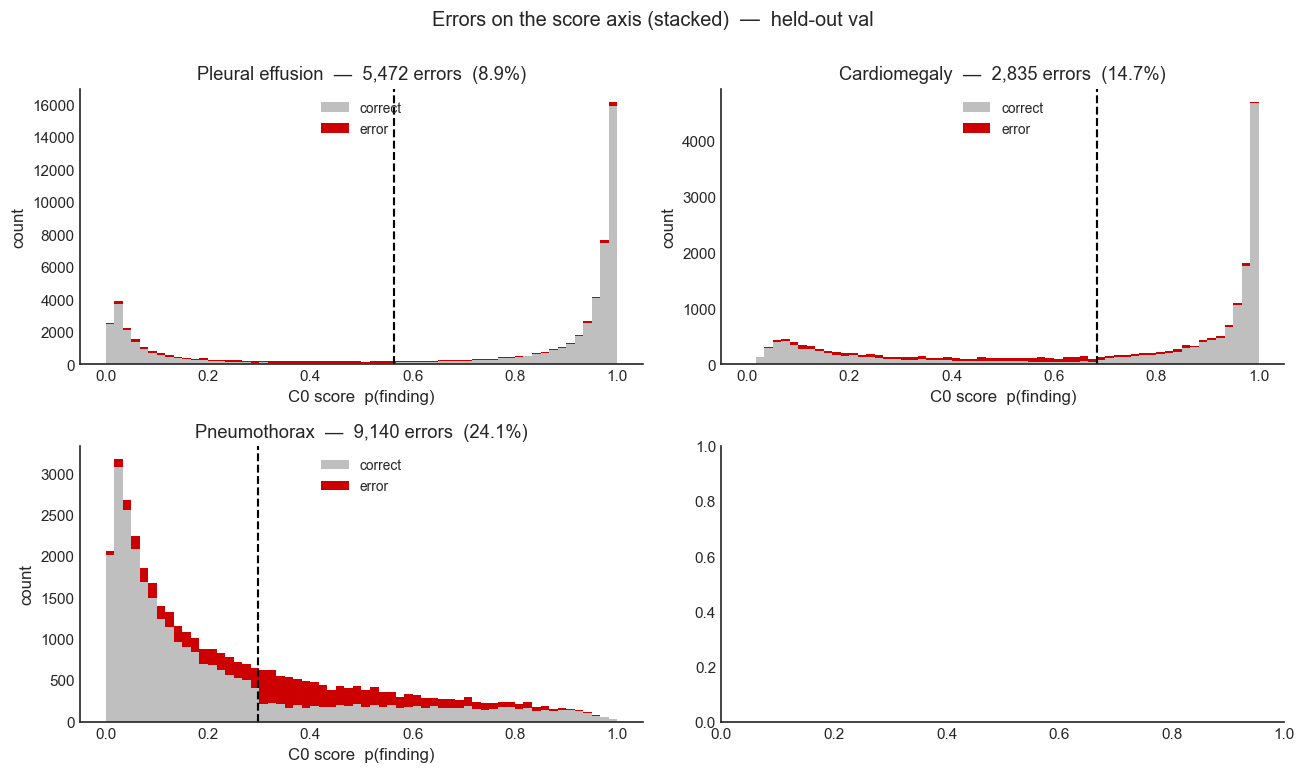

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, t in zip(axes.ravel(), TASKS):
    d = D[(t, 'val')]
    ax.hist([d.prob[d.correct == 1], d.prob[d.correct == 0]], bins=bins, stacked=True,
            color=[C_CORRECT, C_ERROR], label=['correct', 'error'])
    ax.axvline(THR[t], color='k', ls='--', lw=1.4)
    m = MET.loc[(TASK_LABEL[t], 'val')]
    ax.set_title(f'{TASK_LABEL[t]}  —  {int(m.n_err):,} errors  ({m.err_rate:.1%})')
    ax.set_xlabel('C0 score  p(finding)'); ax.set_ylabel('count'); ax.legend(loc='upper center')
fig.suptitle('Errors on the score axis (stacked)  —  held-out val', y=1.00, fontsize=13)
fig.tight_layout(); fig.savefig(f'{OUT}/c0_error_mass_stacked.png'); plt.show()

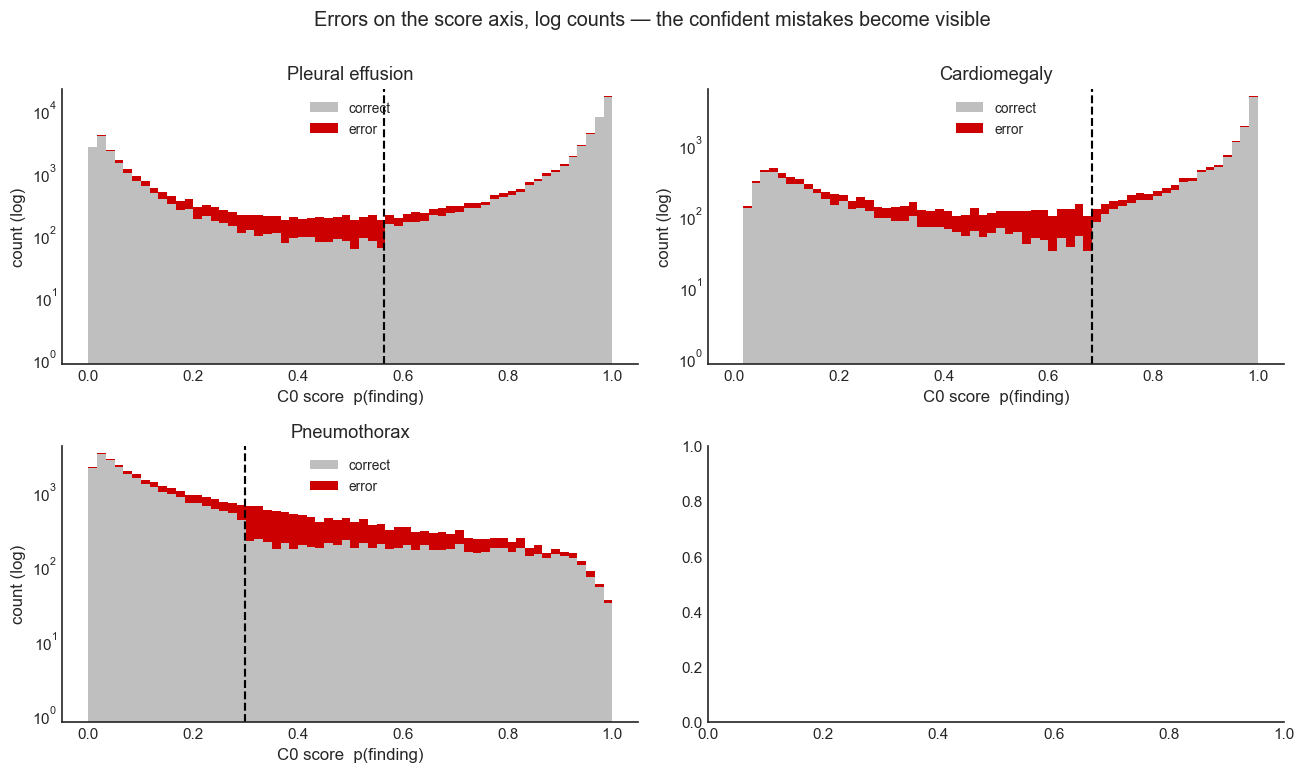

In [8]:
# Same figure, log counts. Necessary for effusion: the p~1.0 spike is ~16k tall, which
# squashes 5.5k errors spread over the rest of the axis into an invisible red smear.
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, t in zip(axes.ravel(), TASKS):
    d = D[(t, 'val')]
    ax.hist([d.prob[d.correct == 1], d.prob[d.correct == 0]], bins=bins, stacked=True,
            color=[C_CORRECT, C_ERROR], label=['correct', 'error'])
    ax.axvline(THR[t], color='k', ls='--', lw=1.4)
    ax.set_yscale('log'); ax.set_ylim(bottom=0.8)
    ax.set_title(TASK_LABEL[t]); ax.set_xlabel('C0 score  p(finding)')
    ax.set_ylabel('count (log)'); ax.legend(loc='upper center')
fig.suptitle('Errors on the score axis, log counts — the confident mistakes become visible',
             y=1.00, fontsize=13)
fig.tight_layout(); fig.savefig(f'{OUT}/c0_error_mass_stacked_log.png'); plt.show()

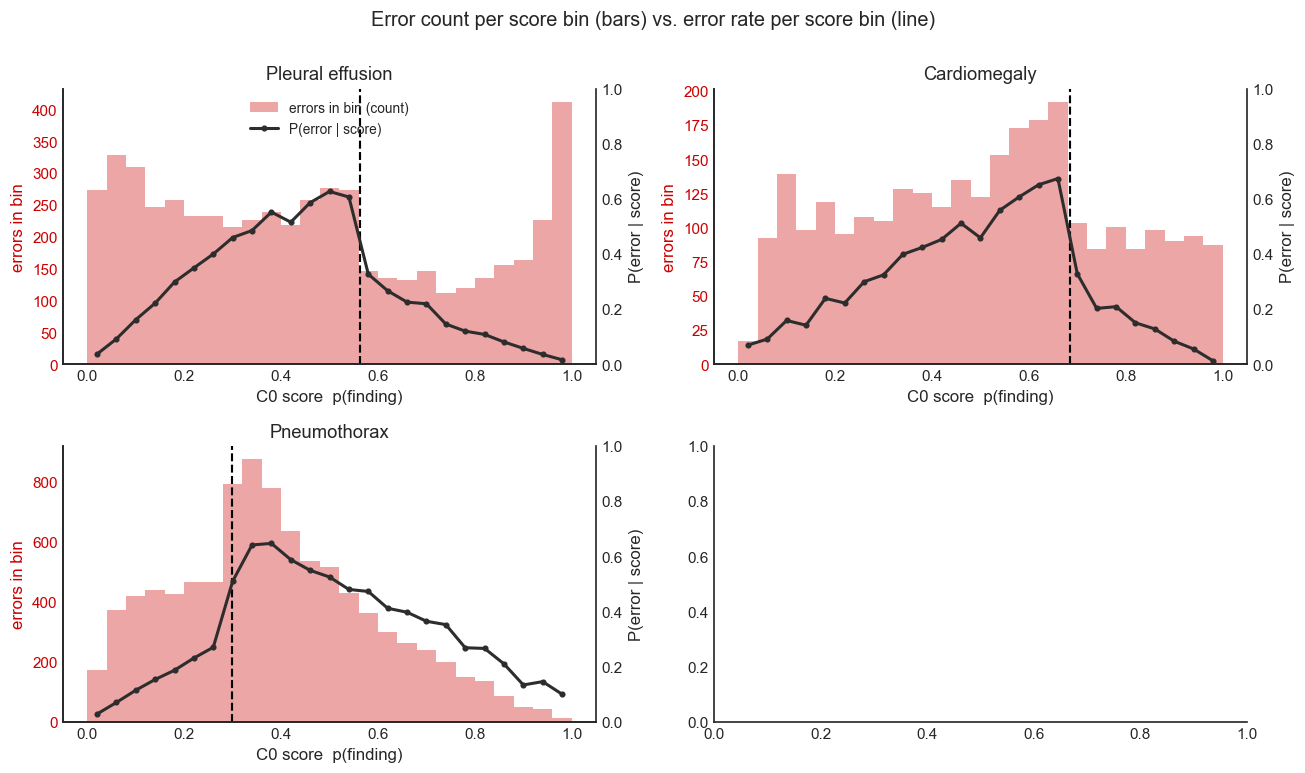

In [9]:
# Errors alone, as a share of each bin's population. Two readings in one panel:
#   bars  = how many errors live in this bin  (absolute supervision available)
#   line  = P(error | score)                  (how hard this region is)
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
edges  = np.linspace(0, 1, 26)
centre = 0.5 * (edges[:-1] + edges[1:])
for ax, t in zip(axes.ravel(), TASKS):
    d = D[(t, 'val')]
    idx = np.clip(np.digitize(d.prob, edges[1:-1]), 0, len(centre) - 1)
    n_bin   = np.bincount(idx, minlength=len(centre))
    n_err   = np.bincount(idx, weights=1 - d.correct, minlength=len(centre))
    rate    = np.divide(n_err, n_bin, out=np.full(len(centre), np.nan), where=n_bin > 0)

    ax.bar(centre, n_err, width=np.diff(edges), color=C_ERROR, alpha=0.35,
           label='errors in bin (count)')
    ax.set_ylabel('errors in bin', color=C_ERROR); ax.tick_params(axis='y', colors=C_ERROR)
    ax.set_xlabel('C0 score  p(finding)')

    ax2 = ax.twinx()
    ax2.plot(centre, rate, color='#2D2D2D', lw=2.0, marker='o', ms=3, label='P(error | score)')
    ax2.set_ylim(0, 1); ax2.set_ylabel('P(error | score)')
    ax2.spines['right'].set_visible(True)
    ax.axvline(THR[t], color='k', ls='--', lw=1.4)
    ax.set_title(TASK_LABEL[t])
    if t == TASKS[0]:
        ax.legend(handles=[Patch(facecolor=C_ERROR, alpha=0.35, label='errors in bin (count)'),
                           Line2D([], [], color='#2D2D2D', lw=2, marker='o', ms=3,
                                  label='P(error | score)')], loc='upper center')
fig.suptitle('Error count per score bin (bars) vs. error rate per score bin (line)',
             y=1.00, fontsize=13)
fig.tight_layout(); fig.savefig(f'{OUT}/c0_error_rate_by_score.png'); plt.show()

### 3b. Which kind of error, and how confident

Splitting the error mass into false positives and false negatives, on the
threshold-relative margin axis. A bar far to the right is a **confident** mistake: the
model was sure and wrong, and no confidence-based method can flag it.

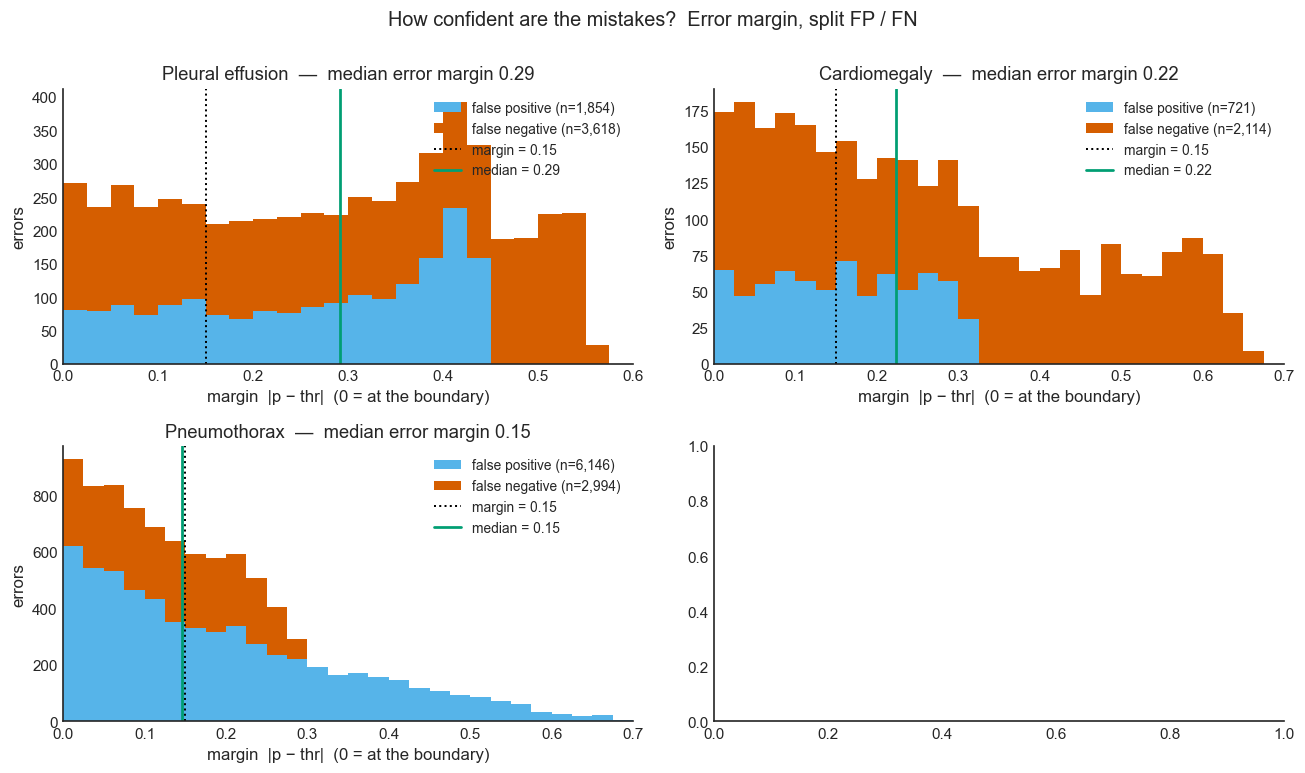

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
mbins = np.linspace(0, 1, 41)
for ax, t in zip(axes.ravel(), TASKS):
    d   = D[(t, 'val')]
    err = d[d.correct == 0]
    fp, fn = err[err.true == 0], err[err.true == 1]
    hi = np.ceil(err.margin.max() * 20) / 20      # trim the empty right-hand half
    ax.hist([fp.margin, fn.margin], bins=mbins, stacked=True, color=[C_FP, C_FN],
            label=[f'false positive (n={len(fp):,})', f'false negative (n={len(fn):,})'])
    med = err.margin.median()
    ax.axvline(0.15, color='k', ls=':', lw=1.3)
    ax.axvline(med,  color='#009E73', lw=1.8)
    ax.set_xlim(0, hi)
    ax.set_title(f'{TASK_LABEL[t]}  —  median error margin {med:.2f}')
    ax.set_xlabel('margin  |p − thr|  (0 = at the boundary)'); ax.set_ylabel('errors')
    h, l = ax.get_legend_handles_labels()
    h += [Line2D([], [], color='k', ls=':', lw=1.3),
          Line2D([], [], color='#009E73', lw=1.8)]
    l += ['margin = 0.15', f'median = {med:.2f}']
    ax.legend(h, l, loc='upper right', framealpha=0.9)
fig.suptitle('How confident are the mistakes?  Error margin, split FP / FN', y=1.00, fontsize=13)
fig.tight_layout(); fig.savefig(f'{OUT}/c0_error_margin_fpfn.png'); plt.show()

### 3c. Rejection curve — how much of the error mass confidence alone can reach

Order samples by margin (least confident first) and defer that prefix to a human.
The curve is *cumulative share of all errors captured* against *share of the dataset
deferred*. This is exactly the MSP baseline any error-prediction method has to beat, so
its shape sets the headroom available.

The diagonal is what a random referrer achieves. The higher above the diagonal, the more
the errors are already explained by low confidence — and the **less** room there is for a
method that adds information beyond confidence.

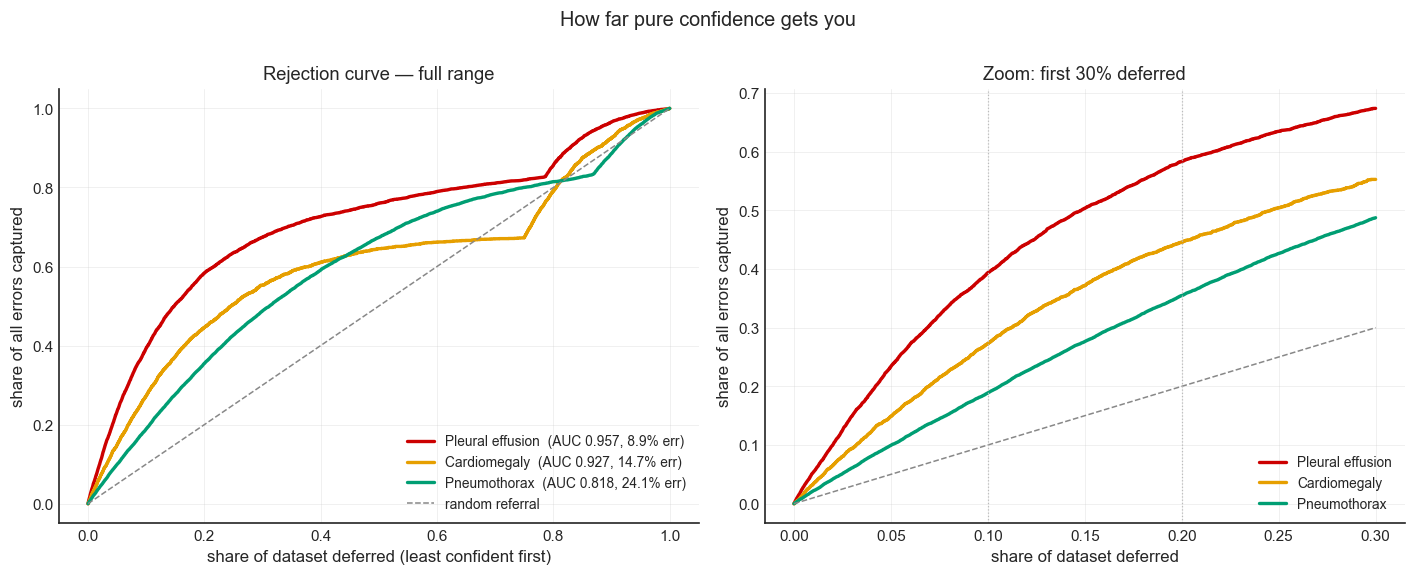

,caught @ 5%,caught @ 10%,caught @ 20%,caught @ 30%,caught @ 50%,lift @ 5%,lift @ 10%,lift @ 20%,lift @ 30%,lift @ 50%
Pleural effusion,0.2339,0.3936,0.5835,0.6738,0.7602,4.6784,3.9364,2.9176,2.2460,1.5205
Cardiomegaly,0.1489,0.2727,0.4459,0.5527,0.6451,2.9771,2.7266,2.2293,1.8424,1.2903
Pneumothorax,0.0994,0.1887,0.3548,0.4875,0.6734,1.9886,1.8873,1.7741,1.6250,1.3468


In [11]:
def rejection_curve(d):
    o = d.sort_values('margin')                    # least confident first
    err = (1 - o.correct.values)
    return (np.arange(1, len(o) + 1) / len(o), np.cumsum(err) / max(err.sum(), 1))

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
ax = axes[0]
for t, col in zip(TASKS, [C_ERROR, '#E69F00', '#009E73', '#0072B2']):
    x, y = rejection_curve(D[(t, 'val')])
    m = MET.loc[(TASK_LABEL[t], 'val')]
    ax.plot(x, y, lw=2.2, color=col,
            label=f'{TASK_LABEL[t]}  (AUC {m.AUC:.3f}, {m.err_rate:.1%} err)')
ax.plot([0, 1], [0, 1], color='#888', ls='--', lw=1.0, label='random referral')
ax.set_xlabel('share of dataset deferred (least confident first)')
ax.set_ylabel('share of all errors captured')
ax.set_title('Rejection curve — full range'); ax.legend(loc='lower right'); ax.grid(alpha=0.3)

ax = axes[1]
for t, col in zip(TASKS, [C_ERROR, '#E69F00', '#009E73', '#0072B2']):
    x, y = rejection_curve(D[(t, 'val')])
    k = x <= 0.30
    ax.plot(x[k], y[k], lw=2.2, color=col, label=TASK_LABEL[t])
ax.plot([0, 0.30], [0, 0.30], color='#888', ls='--', lw=1.0)
for v in (0.10, 0.20):
    ax.axvline(v, color='#bbb', lw=0.8, ls=':')
ax.set_xlabel('share of dataset deferred'); ax.set_ylabel('share of all errors captured')
ax.set_title('Zoom: first 30% deferred'); ax.legend(loc='lower right'); ax.grid(alpha=0.3)
fig.suptitle('How far pure confidence gets you', y=1.00, fontsize=13)
fig.tight_layout(); fig.savefig(f'{OUT}/c0_error_rejection.png'); plt.show()

# Absolute capture is not comparable across tasks with different error rates, so report
# lift over random referral (capture / fraction deferred) alongside it.
QS = (0.05, 0.10, 0.20, 0.30, 0.50)
rej = {}
for t in TASKS:
    x, y = rejection_curve(D[(t, 'val')])
    row = {}
    for q in QS:
        c = np.interp(q, x, y)
        row[f'caught @ {int(q*100)}%'] = c
        row[f'lift @ {int(q*100)}%']   = c / q
    rej[TASK_LABEL[t]] = row
REJ = pd.DataFrame(rej).T
REJ[[c for c in REJ.columns if c.startswith('caught')] +
    [c for c in REJ.columns if c.startswith('lift')]]

### 3d. Calibration

If the model were calibrated, a stated confidence of 0.95 would be wrong 5% of the time.
Points below the diagonal are **over-confidence** — the source of the confident errors in
§3b, and the reason the tails in §3a are not empty.

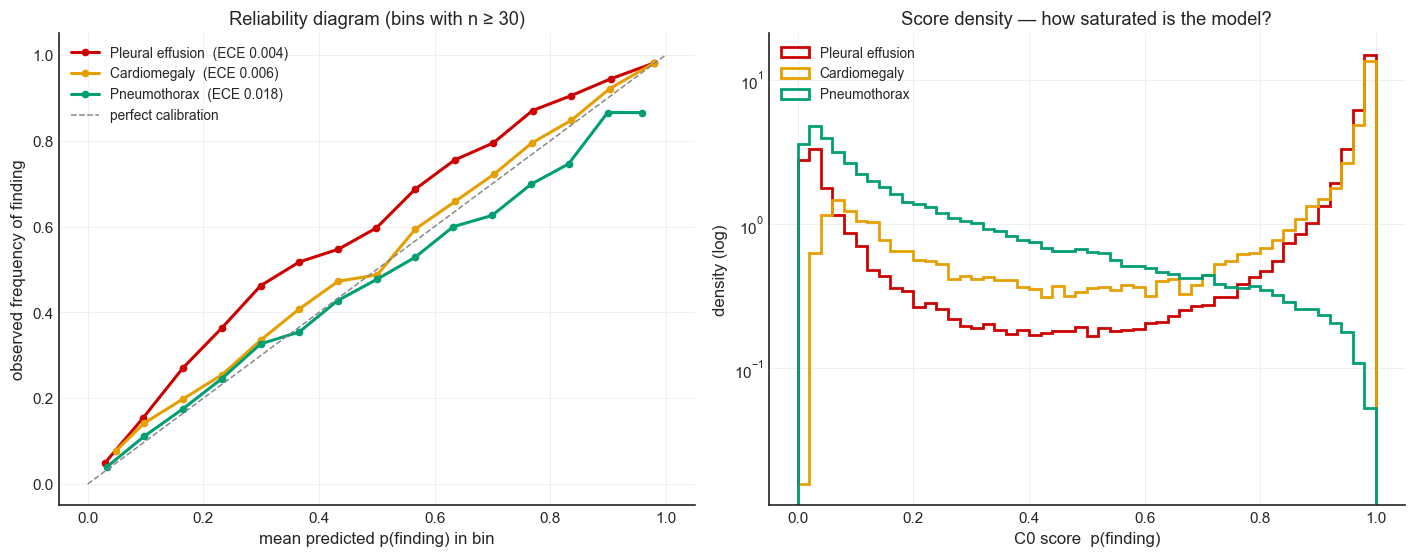

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
ax = axes[0]
nb = 15
edges = np.linspace(0, 1, nb + 1)
for t, col in zip(TASKS, [C_ERROR, '#E69F00', '#009E73', '#0072B2']):
    d = D[(t, 'val')]
    idx = np.clip(np.digitize(d.prob, edges[1:-1]), 0, nb - 1)
    xs, ys = [], []
    for b in range(nb):
        m = idx == b
        if m.sum() >= 30:
            xs.append(d.prob[m].mean()); ys.append(d.true[m].mean())
    ax.plot(xs, ys, marker='o', ms=4, lw=2.0, color=col,
            label=f'{TASK_LABEL[t]}  (ECE {MET.loc[(TASK_LABEL[t], "val"), "ECE"]:.3f})')
ax.plot([0, 1], [0, 1], color='#888', ls='--', lw=1.0, label='perfect calibration')
ax.set_xlabel('mean predicted p(finding) in bin'); ax.set_ylabel('observed frequency of finding')
ax.set_title('Reliability diagram (bins with n ≥ 30)'); ax.legend(loc='upper left'); ax.grid(alpha=0.3)

ax = axes[1]
for t, col in zip(TASKS, [C_ERROR, '#E69F00', '#009E73', '#0072B2']):
    d = D[(t, 'val')]
    ax.hist(d.prob, bins=np.linspace(0, 1, 51), histtype='step', lw=1.8, color=col,
            density=True, label=TASK_LABEL[t])
ax.set_yscale('log')
ax.set_xlabel('C0 score  p(finding)'); ax.set_ylabel('density (log)')
ax.set_title('Score density — how saturated is the model?'); ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(f'{OUT}/c0_error_calibration.png'); plt.show()

---
## §4 — Saturation: the comparison that matters

The headline problem with the effusion C0 is **not** that it has too few errors — it has
more error examples than cardiomegaly or RSNA have *samples*. The problem is that its
score distribution is saturated: almost all of its mass, and most of its errors, sit far
from the decision boundary.

`band` below = margin ≤ 0.15 (within 0.15 of that task's own threshold).

In [13]:
rows = []
for t in TASKS:
    for s, sname in [('val', 'C0-val'), ('c2', 'C2 set')]:
        d = D[(t, s)]
        err = d.correct == 0
        inb = d.margin <= 0.15
        rows.append({
            'task': TASK_LABEL[t], 'split': sname, 'n': len(d),
            'AUC': roc_auc_score(d.true, d.prob), 'acc': d.correct.mean(),
            'n_err': int(err.sum()), 'err_rate': err.mean(),
            'data_in_band': inb.mean(),
            'errors_in_band': (inb & err).sum() / max(err.sum(), 1),
            'err_rate_in_band': err[inb].mean() if inb.any() else np.nan,
            'err_rate_out_band': err[~inb].mean() if (~inb).any() else np.nan,
            'median_err_margin': d.margin[err].median(),
        })
BAND = pd.DataFrame(rows).set_index(['task', 'split'])
BAND.astype({'n': int, 'n_err': int})

n    AUC    acc  n_err  err_rate  data_in_band  errors_in_band  err_rate_in_band  err_rate_out_band  median_err_margin
task             split                                                                                                                             
Pleural effusion C0-val  61442 0.9566 0.9109   5472    0.0891        0.0604          0.2738            0.4039             0.0688             0.2910
                 C2 set  45155 0.9545 0.9172   3737    0.0828        0.0564          0.2713            0.3980             0.0639             0.2909
Cardiomegaly     C0-val  19290 0.9268 0.8530   2835    0.1470        0.1397          0.3534            0.3718             0.1105             0.2238
                 C2 set  13929 0.9370 0.8762   1725    0.1238        0.1236          0.3687            0.3693             0.0892             0.2146
Pneumothorax     C0-val  37916 0.8182 0.7589   9140    0.2411        0.3227          0.5125            0.3829             0.1735             0.1457
                 C2 set  27722 0.8131 0.7442   7092    0.2558        0.3354          0.5155            0.3932             0.1865             0.1448

ValueError: 'c' argument has 4 elements, which is inconsistent with 'x' and 'y' with size 3.

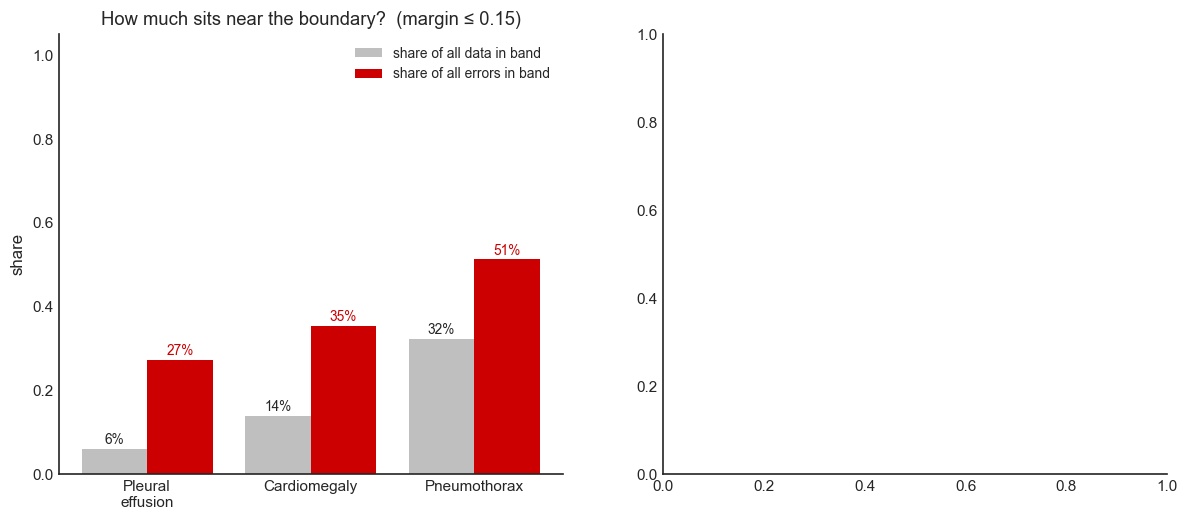

In [15]:
# The money plot: error supply (how much is there) vs error reachability (where it sits).
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
sub  = BAND.xs('C0-val', level='split')
cols = [C_ERROR, '#E69F00', '#009E73', '#0072B2']
order = [TASK_LABEL[t] for t in TASKS]
sub = sub.loc[order]

ax = axes[0]
x = np.arange(len(sub))
ax.bar(x - 0.2, sub.data_in_band,   width=0.4, color='#BFBFBF', label='share of all data in band')
ax.bar(x + 0.2, sub.errors_in_band, width=0.4, color=C_ERROR,   label='share of all errors in band')
for i, (a, b) in enumerate(zip(sub.data_in_band, sub.errors_in_band)):
    ax.text(i - 0.2, a + 0.012, f'{a:.0%}', ha='center', fontsize=9)
    ax.text(i + 0.2, b + 0.012, f'{b:.0%}', ha='center', fontsize=9, color=C_ERROR)
ax.set_xticks(x, [s.replace(' ', '\n') for s in sub.index])
ax.set_ylabel('share'); ax.set_ylim(0, 1.05)
ax.set_title('How much sits near the boundary?  (margin ≤ 0.15)'); ax.legend()

ax = axes[1]
ax.scatter(sub.AUC, sub.errors_in_band, s=[np.sqrt(n) * 3 for n in sub.n_err],
           c=cols[:len(sub)], zorder=3, edgecolor='k', lw=0.6)
for (name, r), col in zip(sub.iterrows(), cols):
    ax.annotate(f'{name}\n{int(r.n_err):,} errors', xy=(r.AUC, r.errors_in_band),
                xytext=(0, -30), textcoords='offset points', ha='center',
                fontsize=9.5, color=col)
ax.set_xlabel('C0 AUC'); ax.set_ylabel('share of errors within margin 0.15')
ax.set_title('Weaker C0 → errors concentrate near the boundary\n(marker area scales with number of errors)')
ax.grid(alpha=0.3); ax.set_ylim(0, 1.0)
fig.tight_layout(); fig.savefig(f'{OUT}/c0_error_saturation.png'); plt.show()

In [15]:
# Data-driven summary — recomputed, not hard-coded, so it cannot go stale.
v = {t: MET.loc[(TASK_LABEL[t], 'val')] for t in TASKS}
b = {t: BAND.loc[(TASK_LABEL[t], 'C0-val')] for t in TASKS}
print('C0 held-out (val) summary\n' + '=' * 78)
for t in TASKS:
    print(f'{TASK_LABEL[t]:<18} AUC {v[t].AUC:.3f}   acc {v[t].acc:.3f}   '
          f'{int(v[t].n_err):>6,} errors ({v[t].err_rate:5.1%})   '
          f'{b[t].errors_in_band:5.1%} of them within margin 0.15   '
          f'median err margin {b[t].median_err_margin:.2f}')

e = 'effusion'
print('\nEffusion in context\n' + '=' * 78)
print(f'  error examples available : {int(v[e].n_err):,}  '
      f'(vs {int(v["cardiomegaly"].n_err):,} cardiomegaly, {int(v["rsna_pneumonia"].n_err):,} RSNA)')
print(f'  ... so error SUPPLY is not the bottleneck.')
print(f'  errors within margin 0.15: {b[e].errors_in_band:.1%}  '
      f'(vs {b["pneumothorax"].errors_in_band:.1%} pneumothorax)')
print(f'  median error margin      : {b[e].median_err_margin:.2f}  '
      f'(vs {b["pneumothorax"].median_err_margin:.2f} pneumothorax)')
print(f'  error rate in band       : {b[e].err_rate_in_band:.1%}   '
      f'out of band: {b[e].err_rate_out_band:.1%}')
print('\nHow strong is the confidence baseline it must beat?\n' + '=' * 78)
for t in TASKS:
    c10 = np.interp(0.10, *rejection_curve(D[(t, 'val')]))
    print(f'  {TASK_LABEL[t]:<18} least-confident 10% deferred catches {c10:5.1%} of errors '
          f'(lift {c10/0.10:.1f}x over random)')
print('\n  -> confidence ranks effusion errors BEST of the four. The MSP baseline is hardest')
print('     to beat exactly where C0 is strongest, which is the real argument for moving the')
print('     headline task to pneumothorax/RSNA or building a ladder of weaker effusion C0s.')

C0 held-out (val) summary
Pleural effusion   AUC 0.957   acc 0.911    5,472 errors ( 8.9%)   27.4% of them within margin 0.15   median err margin 0.29
Cardiomegaly       AUC 0.927   acc 0.853    2,835 errors (14.7%)   35.3% of them within margin 0.15   median err margin 0.22
RSNA pneumonia     AUC 0.863   acc 0.785    1,119 errors (21.5%)   42.7% of them within margin 0.15   median err margin 0.18
Pneumothorax       AUC 0.818   acc 0.759    9,140 errors (24.1%)   51.2% of them within margin 0.15   median err margin 0.15

Effusion in context
  error examples available : 5,472  (vs 2,835 cardiomegaly, 1,119 RSNA)
  ... so error SUPPLY is not the bottleneck.
  errors within margin 0.15: 27.4%  (vs 51.2% pneumothorax)
  median error margin      : 0.29  (vs 0.15 pneumothorax)
  error rate in band       : 40.4%   out of band: 6.9%

How strong is the confidence baseline it must beat?
  Pleural effusion   least-confident 10% deferred catches 39.4% of errors (lift 3.9x over random)
  Cardiomega

---
## What this says

1. **The effusion C0 is not error-starved.** AUC 0.954 / accuracy 91.7% on held-out data,
   which is ~5.5k errors on C0-val and 3.7k in the C2 set — more error examples than
   cardiomegaly or RSNA have samples in total. The often-quoted "> 95%" is the **AUC**,
   not the accuracy.

2. **It is saturated, and that is the real constraint.** The median effusion error sits far
   from the threshold — these are *confident* mistakes. Contrast pneumothorax, whose errors
   pile up against the boundary.

3. **Confidence is already a strong error-ranker on effusion, and that is the actual bad
   news.** Deferring the least-confident 10% of effusion cases catches ~39% of all its
   errors — a ~3.9x lift over random referral, the steepest curve of the four tasks
   (pneumothorax: ~19%, ~1.9x). So the MSP baseline is *hardest* to beat precisely where
   C0 is strongest. Saturation does not open headroom for a method that adds information
   beyond confidence; it closes it. It also removes the ambiguous region a counterfactual
   perturbation can move a sample across — a confident error needs a large, semantically
   real edit to flip, where a boundary error needs a nudge.

4. **The class imbalance is the operational nuisance.** ~8% errors means an ~11:1 target
   imbalance for the downstream model — a class-weight and metric-choice problem
   (AUPRC, balanced accuracy), not a reason to degrade C0.

5. **Cross-task, error-mass concentration tracks C0 weakness.** The right panel of §4 is
   the empirical version of the argument for building a *ladder* of C0s rather than one
   hand-crippled model: as AUC drops, errors migrate toward the boundary and the whole
   problem changes character. That is a result worth reporting, not just a nuisance to
   engineer around.